In [296]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [297]:
df = pd.read_csv('placement.csv')
df = df.drop(columns = ['Unnamed: 0']) #dropping an extra index column

print(df.shape)

(100, 3)


<Axes: xlabel='cgpa', ylabel='iq'>

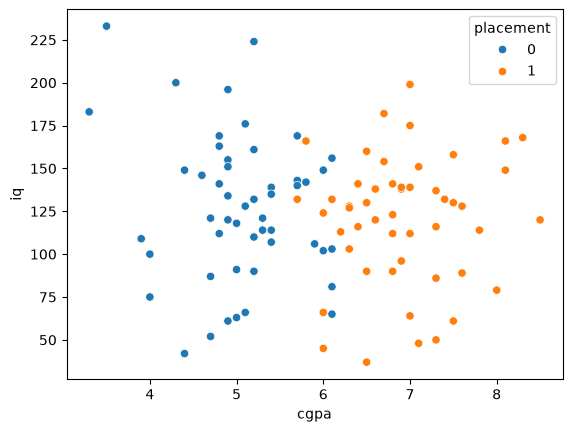

In [298]:
sns.scatterplot(
    data = df,
    x = 'cgpa',
    y = 'iq',
    hue = 'placement'
)

In [299]:
X = df.iloc[:, 0:2] #select input features - column cgpa and iq
y = df.iloc[:, 2] #select output - column placement

print(X.shape)
type(X)

(100, 2)


pandas.DataFrame

In [300]:
from sklearn.linear_model import Perceptron
p = Perceptron()

In [301]:
# p.fit(input features, output)
p.fit(X, y)

,"penalty penalty: {'l2','l1','elasticnet'}, default=NoneThe penalty (aka regularization term) to be used.",None
,"alpha alpha: float, default=0.0001Constant that multiplies the regularization term if regularization isused.",0.0001
,"l1_ratio l1_ratio: float, default=0.15The Elastic Net mixing parameter, with `0 <= l1_ratio <= 1`.`l1_ratio=0` corresponds to L2 penalty, `l1_ratio=1` to L1.Only used if `penalty='elasticnet'`... versionadded:: 0.24",0.15
,"fit_intercept fit_intercept: bool, default=TrueWhether the intercept should be estimated or not. If False, thedata is assumed to be already centered.",True
,"max_iter max_iter: int, default=1000The maximum number of passes over the training data (aka epochs).It only impacts the behavior in the ``fit`` method, and not the:meth:`partial_fit` method... versionadded:: 0.19",1000
,"tol tol: float or None, default=1e-3The stopping criterion. If it is not None, the iterations will stopwhen (loss > previous_loss - tol)... versionadded:: 0.19",0.001
,"shuffle shuffle: bool, default=TrueWhether or not the training data should be shuffled after each epoch.",True
,"verbose verbose: int, default=0The verbosity level.",0
,"eta0 eta0: float, default=1Constant by which the updates are multiplied.",1.0
,"n_jobs n_jobs: int, default=NoneThe number of CPUs to use to do the OVA (One Versus All, formulti-class problems) computation.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"random_state random_state: int, RandomState instance or None, default=0Used to shuffle the training data, when ``shuffle`` is set to``True``. Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",0


In [302]:
# %pip install mlxtend
# installed mlxtend

# X.to_numpy()

/opt/anaconda3/lib/python3.14/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but Perceptron was fitted with feature names
  warnings.warn(


<Axes: >

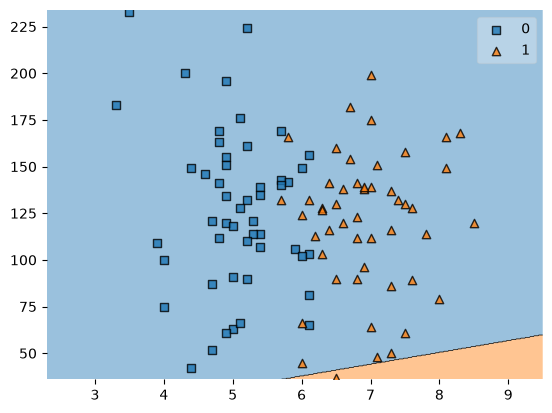

In [303]:
from mlxtend.plotting import plot_decision_regions
# used to visualize decision boundary learned by a machine learning classification model.

plot_decision_regions(X.to_numpy(), y.to_numpy(), clf = p)

In [304]:
# Training

epochs = 10000
lr = 0.01

X.insert(0, 'bias', 1.)
weights = np.ones(X.shape[1]) #[w0, w1, w2]

X_arr = X.to_numpy()
y_arr = y.to_numpy()


In [305]:
# feature scaling - Normalisation

from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()

features_scaled = scaler.fit_transform(X.iloc[:, 1:3]) #use fit on input features and transform on val, test
X_scaled = np.insert(features_scaled, 0, 1.0, axis=1) #axis=0 for new row


In [306]:
def step(z):
    return 1 if z >= 0 else 0

for i in range(epochs):
    j = np.random.randint(0, len(X_arr)) #random row index

    y_hat = step(np.dot(weights, X_scaled[j]))
        
    weights = weights + (y_arr[j] - y_hat) * lr * X_scaled[j]

p.intercept_ = weights[0]
p.coef_ = weights[1:].reshape(1, -1)  #-1 calculates number of columns based on number of elements in array because p.coef_ is a 2D array so reshaping

In [307]:
print(p.coef_)
print(p.intercept_)

[[0.50826923 0.01561224]]
-0.29000000000000087


(0.0, 1.0)

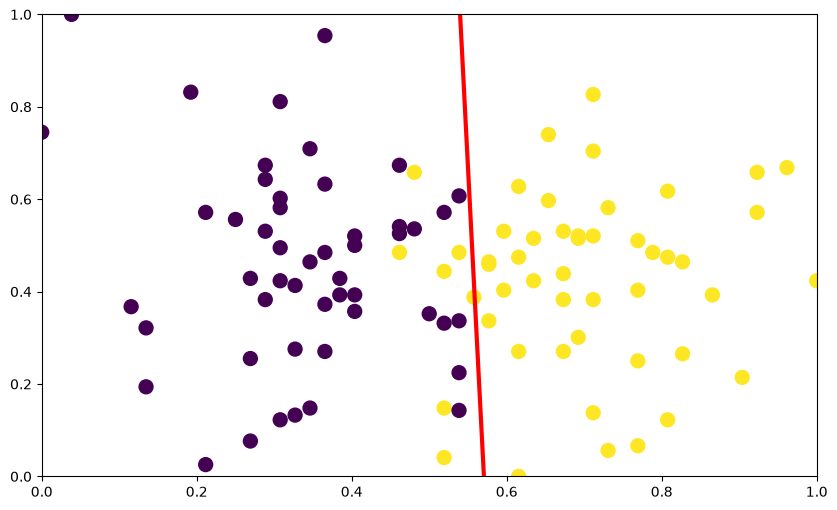

In [308]:
# Ax + By + C = 0 -> y = mx + b
# m = -A/B
# b = -C/B

m = -p.coef_[0][0] / p.coef_[0][1]
b = -p.intercept_ / p.coef_[0][1]

x_input = np.linspace(0,1,100) #generates 100 evenly spaced values b/w 0 and 1
y_input = m*x_input + b

#figure of width = 10 and height = 6
plt.figure(figsize=(10,6))

#decision boundary
plt.plot(x_input,y_input,color='red',linewidth=3)

#actual datapoints (feature on x-axis, y-axis, color pts acc to class label, marker size)
plt.scatter(X_scaled[:,1],X_scaled[:,2],c=y_arr,s=100)

plt.ylim(0,1)
plt.xlim(0, 1)

In [309]:
# prediction

def predict(cgpa, iq):
    x_new = np.array([[cgpa, iq]])

    x_new_scaled = scaler.transform(x_new)

    x_new_scaled = np.insert(x_new_scaled, 0, 1.0, axis=1)

    z = np.dot(weights, x_new_scaled[0])

    return 1 if z >= 0 else 0

test_cgpa = 6.98
test_iq = 90

print(predict(test_cgpa, test_iq))

1


/opt/anaconda3/lib/python3.14/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but MinMaxScaler was fitted with feature names
  warnings.warn(
